# 04. 力学モデル・マルチレベル・空間充填・バックボーンレイアウト

このノートブックでは、`egraph` v6 が提供する **力学モデル（Force-Directed）**、**マルチレベル法**、**構造エントロピー変調**、**空間充填曲線（SFC）**、および **バックボーン抽出／粗視化バックボーン初期化** の全 10 種の API を網羅します。

- **力学モデル**: `ForceAtlas2Solver`, `FruchtermanReingoldSolver`, `LinLogSolver`, `GemSolver`
- **マルチレベル・構造変調・空間充填**: `YifanHuSolver`, `SelLayoutSolver`, `SfcLayoutSolver`
- **バックボーン抽出・初期化**: `extract_quadrilateral_backbone`, `BackboneSolver`, `coarse_backbone_init`

> `egraph` はレイアウト計算と評価指標の算出のみに使用し、描画はすべて `matplotlib` で行います。

In [ ]:
!pip install -q --pre "egraph==6.0.0a9" matplotlib-fontja

## 1. インポートと描画・評価ヘルパーの定義

ゼロコピーの `layout.coords(copy=False)` と `LineCollection` による共通プロット関数、および `evaluate_metrics` を用いた定量評価ヘルパーを定義します。

In [ ]:
\
import time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection

try:
    import matplotlib_fontja  # noqa: F401
except ImportError:
    pass

import egraph as eg

plt.rcParams["figure.dpi"] = 120


def plot_graph_2d(
    graph: eg.CsrGraph,
    layout: eg.Layout2d,
    ax,
    title: str = "",
    node_size: float = 12.0,
    edge_alpha: float = 0.22,
    node_color: str = "#1f77b4",
):
    '''Plot 2D graph layout strictly with matplotlib LineCollection and scatter.'''
    coords = layout.coords(copy=False)
    indptr = graph.indptr()
    indices = graph.indices()
    segments = [
        [coords[u], coords[int(v)]]
        for u in range(graph.num_nodes)
        for v in indices[int(indptr[u]) : int(indptr[u + 1])]
        if graph.is_directed or u < int(v)
    ]
    if segments:
        ax.add_collection(
            LineCollection(segments, colors="#777777", linewidths=0.5, alpha=edge_alpha, zorder=1)
        )
    ax.scatter(
        coords[:, 0],
        coords[:, 1],
        s=node_size,
        c=node_color,
        edgecolors="white",
        linewidths=0.25,
        zorder=2,
    )
    ax.set_aspect("equal")
    ax.autoscale_view()
    ax.set_xticks([])
    ax.set_yticks([])
    if title:
        ax.set_title(title, fontsize=9.5)


def eval_summary(graph: eg.CsrGraph, layout: eg.Layout2d) -> tuple[float, float, float]:
    '''Evaluate SNS, NP2, and crosslessness via egraph.evaluate_metrics.'''
    m = eg.evaluate_metrics(graph, layout, ["sns", "np2", "crosslessness"])
    return (
        float(m.scale_normalized_stress),
        float(m.neighborhood_preservation_2hop),
        float(m.crosslessness),
    )


g_lesmis = eg.load_dataset("lesmis")
g_qh = eg.load_dataset("qh882")
g_bus = eg.load_dataset("1138_bus")
g_poli = eg.load_dataset("poli")
print(
    f"Loaded datasets: lesmis=({g_lesmis.num_nodes}, {g_lesmis.num_edges}), "
    f"qh882=({g_qh.num_nodes}, {g_qh.num_edges}), "
    f"1138_bus=({g_bus.num_nodes}, {g_bus.num_edges}), "
    f"poli=({g_poli.num_nodes}, {g_poli.num_edges}, disconnected)"
)

Loaded datasets: lesmis=(77, 254), qh882=(882, 1533), 1138_bus=(1138, 1458), poli=(3915, 4119, disconnected)


\
## 2. ForceAtlas2 (`ForceAtlas2Solver`) のモード比較

`ForceAtlas2Solver` は、Barnes-Hut 近似 (`use_barnes_hut`)、対数引力モード (`linlog_mode`)、強重力モード (`strong_gravity`)、およびノード半径を用いた重なり防止モード (`prevent_overlap`, `node_radii`, `default_node_radius`) を備えており、`theta`・`gravity`・`scaling_ratio`・`max_displacement` などすべての設定ゲッタと 3D `LayoutNd` への直接適用に対応しています。

ForceAtlas2 [標準 (Barnes-Hut)                 ] status=completed iter=200/200 prevent_overlap=False max_disp=None len(radii)=882 |  149.2 ms | SNS=0.1662 NP2=0.4996 CR=0.9689


ForceAtlas2 [LinLog モード (linlog_mode=True)   ] status=completed iter=200/200 prevent_overlap=False max_disp=None len(radii)=882 |  155.2 ms | SNS=0.3678 NP2=0.4152 CR=0.9412
ForceAtlas2 [強重力 (strong_gravity=True)       ] status=completed iter=200/200 prevent_overlap=False max_disp=None len(radii)=882 |  121.7 ms | SNS=0.2706 NP2=0.2227 CR=0.9397


ForceAtlas2 [重なり防止 (prevent_overlap=True)    ] status=completed iter=200/200 prevent_overlap=True max_disp=None len(radii)=882 |  255.2 ms | SNS=0.2542 NP2=0.3480 CR=0.9517
3D LayoutNd SNS (lesmis): FA2=0.1173, FR=0.0995


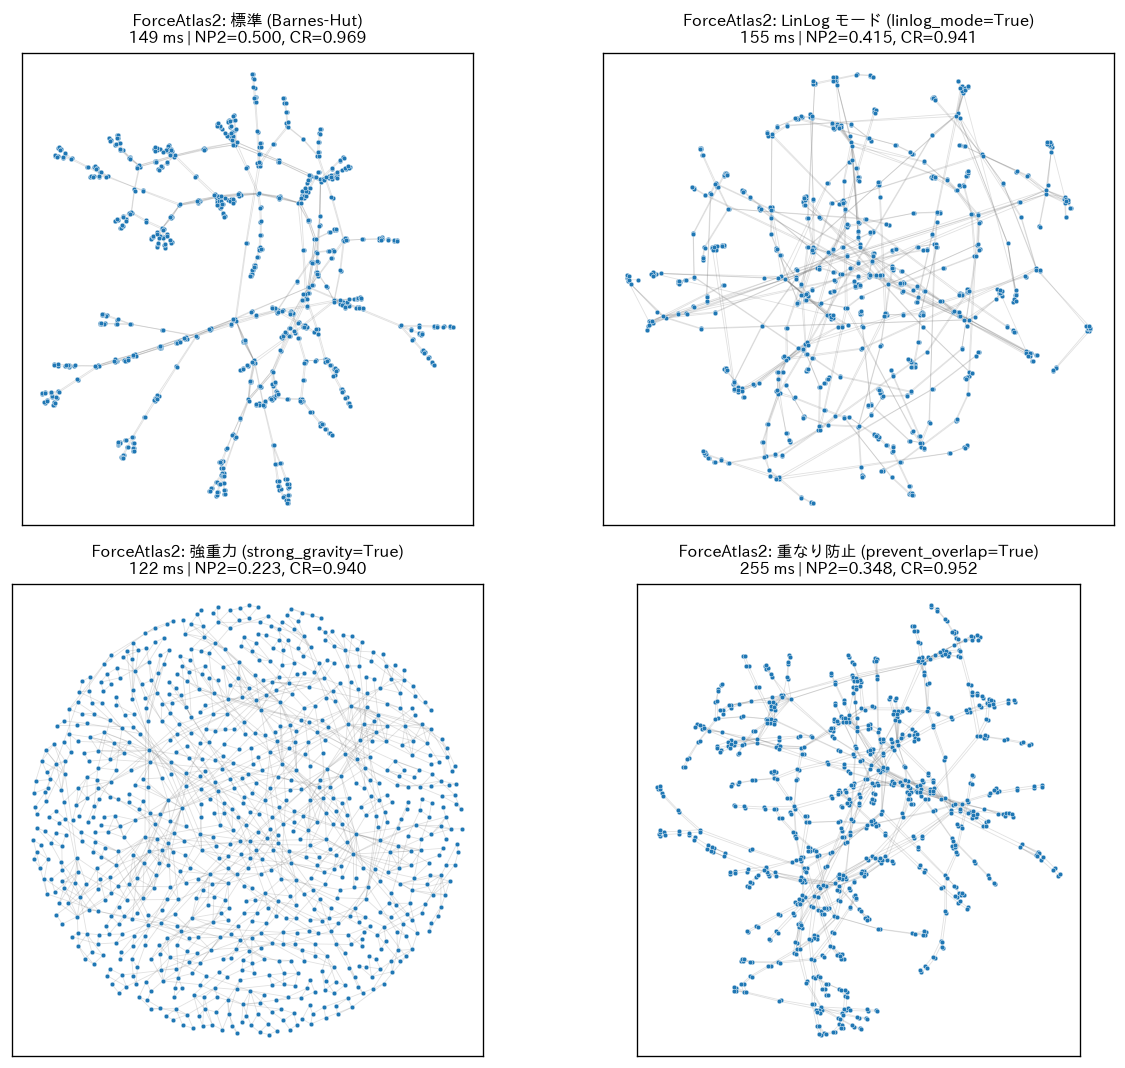

In [ ]:
\
degs_qh = np.array([g_qh.degree(u) for u in range(g_qh.num_nodes)], dtype=np.float64)
radii_qh = 0.4 + 0.25 * np.sqrt(degs_qh)

fa2_configs = [
    ("標準 (Barnes-Hut)", dict(iterations=200, use_barnes_hut=True)),
    ("LinLog モード (linlog_mode=True)", dict(iterations=200, use_barnes_hut=True, linlog_mode=True)),
    ("強重力 (strong_gravity=True)", dict(iterations=200, use_barnes_hut=True, strong_gravity=True, gravity=2.0)),
    (
        "重なり防止 (prevent_overlap=True)",
        dict(
            iterations=200,
            use_barnes_hut=True,
            prevent_overlap=True,
            default_node_radius=1.0,
            node_radii=radii_qh,
        ),
    ),
]

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (label, kwargs) in zip(axes.flat, fa2_configs):
    lay = eg.Layout2d.init(g_qh.num_nodes, seed=42)
    t0 = time.perf_counter()
    solver = eg.ForceAtlas2Solver(g_qh, seed=42, **kwargs)
    status = solver.run(lay)
    ms = (time.perf_counter() - t0) * 1000.0
    sns, np2, cr = eval_summary(g_qh, lay)
    assert lay.is_all_finite()
    print(
        f"ForceAtlas2 [{label:<32}] status={status} iter={solver.iteration}/{solver.total_iterations} "
        f"prevent_overlap={solver.prevent_overlap} max_disp={solver.max_displacement} "
        f"len(radii)={len(solver.node_radii)} | {ms:6.1f} ms | SNS={sns:.4f} NP2={np2:.4f} CR={cr:.4f}"
    )
    plot_graph_2d(g_qh, lay, ax, title=f"ForceAtlas2: {label}\n{ms:.0f} ms | NP2={np2:.3f}, CR={cr:.3f}", node_size=8.0)

# 3D LayoutNd support check for ForceAtlas2 / FR / YifanHu
nd_fa2 = eg.LayoutNd.init(g_lesmis.num_nodes, 3, seed=42)
eg.ForceAtlas2Solver(g_lesmis, iterations=80, seed=42).run(nd_fa2)
nd_fr = eg.LayoutNd.init(g_lesmis.num_nodes, 3, seed=42)
eg.FruchtermanReingoldSolver(g_lesmis, iterations=80, backend="barnes_hut", seed=42).run(nd_fr)
print(
    f"3D LayoutNd SNS (lesmis): FA2={eg.scale_normalized_stress(g_lesmis, nd_fa2):.4f}, "
    f"FR={eg.scale_normalized_stress(g_lesmis, nd_fr):.4f}"
)

plt.tight_layout()
plt.show()

## 3. Fruchterman-Reingold (`FruchtermanReingoldSolver`) と 3 種のバックエンド

`FruchtermanReingoldSolver` は、反発力計算に `"exact"`（厳密 $O(N^2)$）・`"barnes_hut"`（四分木近似）・`"grid"`（空間グリッド近似）の 3 バックエンドをサポートし、協調実行中に冷却温度 `current_temperature` や最適辺長 `optimal_distance` を参照できます。

FR [exact     ] status=completed opt_d=1.0000 end_T=0.0000 |  561.8 ms | SNS=0.1722 NP2=0.3527 CR=0.9613
FR barnes_hut temperature decay (iter, T): [(30, 2.2274), (60, 1.4849), (90, 0.7425), (120, 0.0)]


FR [barnes_hut] status=completed opt_d=1.0000 end_T=0.0000 |  121.0 ms | SNS=0.1404 NP2=0.3958 CR=0.9649


FR [grid      ] status=completed opt_d=1.0000 end_T=0.0000 |  117.4 ms | SNS=0.1979 NP2=0.2828 CR=0.9532


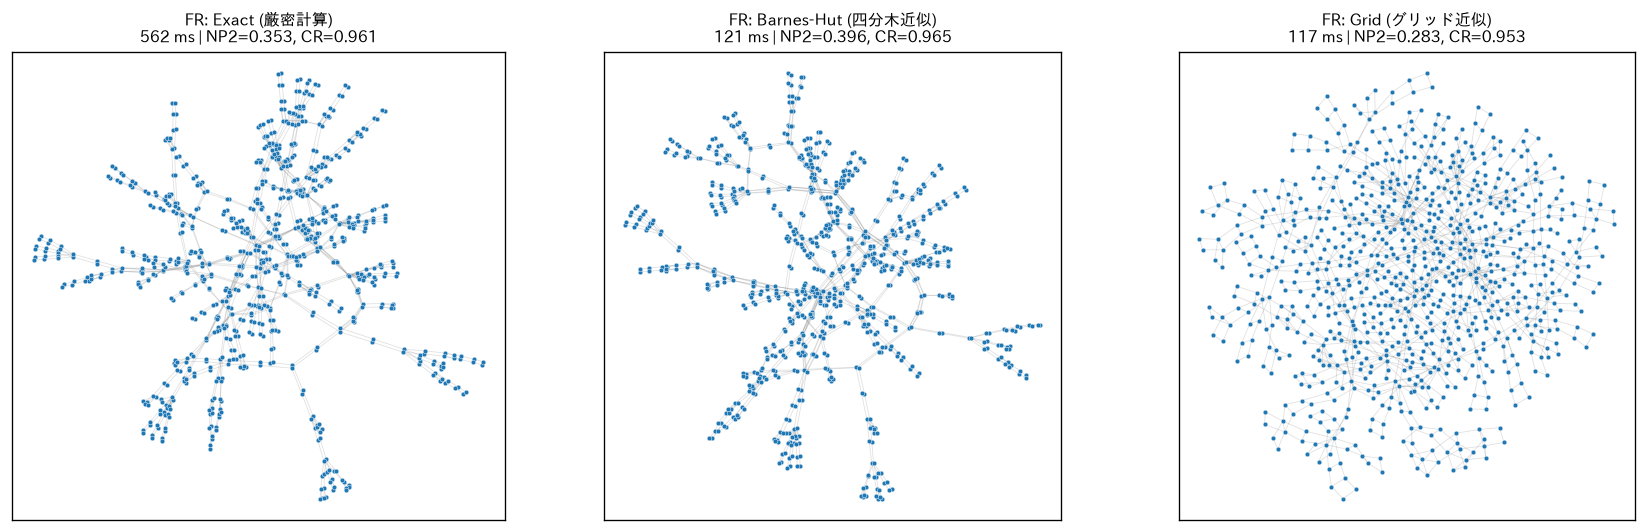

In [ ]:
fr_backends = [
    ("exact", "Exact (厳密計算)"),
    ("barnes_hut", "Barnes-Hut (四分木近似)"),
    ("grid", "Grid (グリッド近似)"),
]

fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.5))
for ax, (backend, jp_name) in zip(axes, fr_backends):
    lay = eg.Layout2d.init(g_qh.num_nodes, seed=42)
    t0 = time.perf_counter()
    solver = eg.FruchtermanReingoldSolver(g_qh, iterations=120, backend=backend, seed=42)
    if backend == "barnes_hut":
        temps = []
        while not solver.is_finished:
            solver.run_steps(lay, 30)
            temps.append((solver.iteration, round(solver.current_temperature, 4)))
        status = solver.status
        print(f"FR barnes_hut temperature decay (iter, T): {temps}")
    else:
        status = solver.run(lay)
    ms = (time.perf_counter() - t0) * 1000.0
    sns, np2, cr = eval_summary(g_qh, lay)
    assert lay.is_all_finite()
    print(
        f"FR [{backend:<10}] status={status} opt_d={solver.optimal_distance:.4f} "
        f"end_T={solver.current_temperature:.4f} | {ms:6.1f} ms | SNS={sns:.4f} NP2={np2:.4f} CR={cr:.4f}"
    )
    plot_graph_2d(g_qh, lay, ax, title=f"FR: {jp_name}\n{ms:.0f} ms | NP2={np2:.3f}, CR={cr:.3f}", node_size=8.0)

plt.tight_layout()
plt.show()

\
## 4. Noack LinLog (`LinLogSolver`) と GEM (`GemSolver`)

- `LinLogSolver` は Noack (2009) の $(a, r)$-LinLog エネルギーモデルを実装し、`repulsion_model` として `"edge_repulsion"`（辺密度ベースの反発・コミュニティ分離向き）と `"node_repulsion"`（頂点ベースの反発）を切り替えられます。`energy(layout)` は $O(N^2 + |E|)$ 計算となるため、小〜中規模グラフでの前後比較に用います。
- `GemSolver` は適応温度・振動／回転検知を備える古典的手法です。既定値 `max_iterations=None` では `min(4*N, 400)` ラウンドへ安全にキャップされ、大規模グラフでの計算時間暴走を防ぎます（例: `qh882` で `max_iterations=150` を明示指定可能）。

LinLog (edge_repulsion, lesmis)      energy: 103224.20 -> -757884.36 | max_disp=50.00 | 12.8 ms | NP2=0.4876
LinLog (node_repulsion, lesmis)      energy: 2301.43 -> -7962.57 | max_disp=50.00 | 14.0 ms | NP2=0.5579
GemSolver (lesmis, default max_iterations=308): 21.6 ms | NP2=0.7148


GemSolver (qh882, explicit max_iterations=150): 1092.6 ms | SNS=0.1263 NP2=0.4020


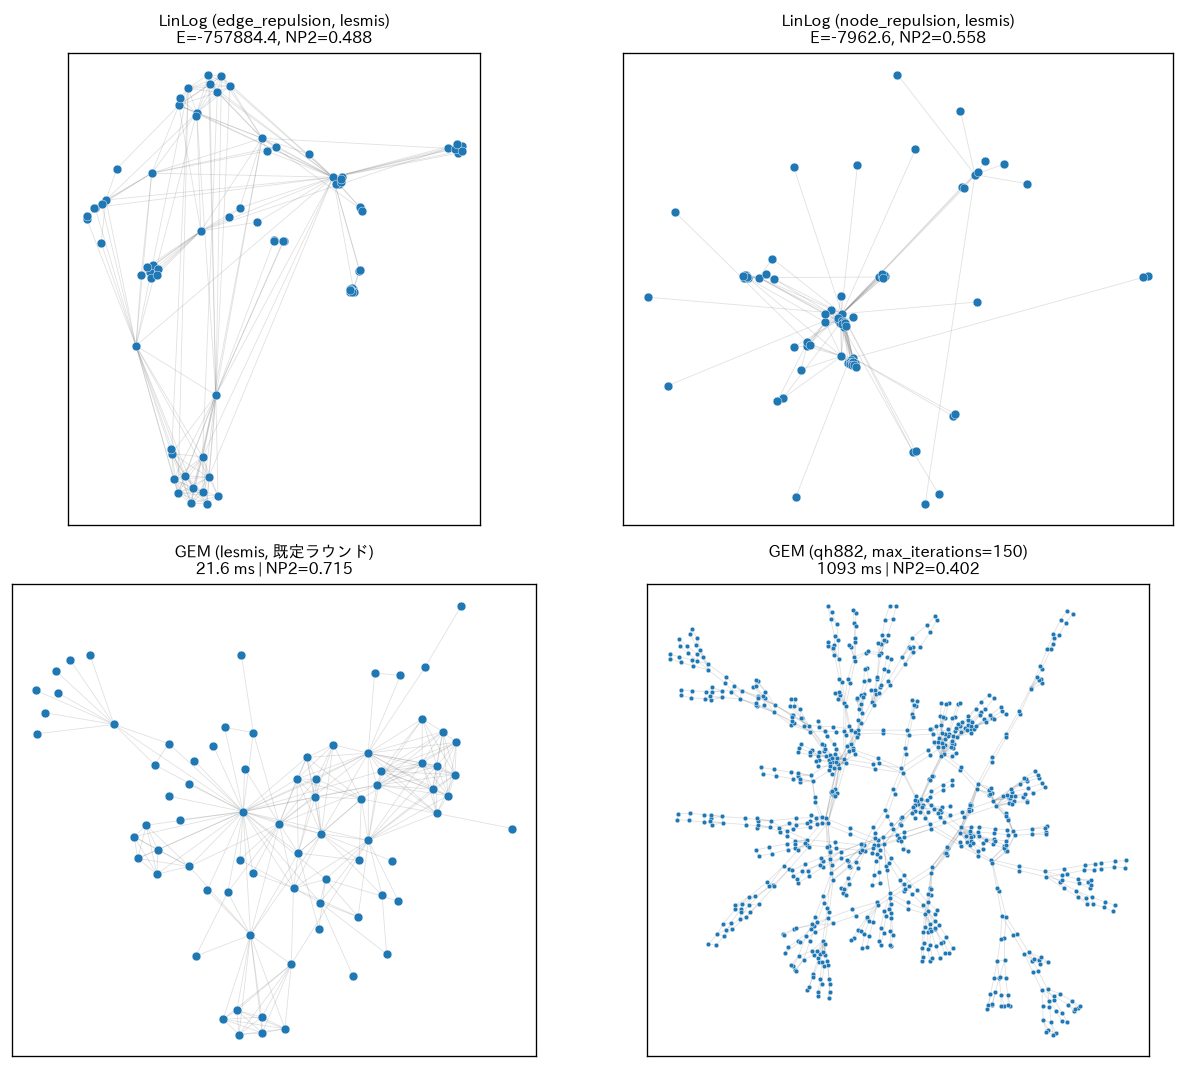

In [ ]:
\
fig, axes = plt.subplots(2, 2, figsize=(11, 9))

# 1-2) LinLogSolver edge_repulsion vs node_repulsion on lesmis
for ax, model, jp_label in [
    (axes[0, 0], "edge_repulsion", "LinLog (edge_repulsion, lesmis)"),
    (axes[0, 1], "node_repulsion", "LinLog (node_repulsion, lesmis)"),
]:
    lay = eg.Layout2d.init(g_lesmis.num_nodes, seed=42)
    solver = eg.LinLogSolver(g_lesmis, iterations=200, repulsion_model=model, seed=42)
    e_init = solver.energy(lay)
    t0 = time.perf_counter()
    solver.run(lay)
    ms = (time.perf_counter() - t0) * 1000.0
    e_final = solver.energy(lay)
    sns, np2, cr = eval_summary(g_lesmis, lay)
    print(
        f"{jp_label:<36} energy: {e_init:.2f} -> {e_final:.2f} | "
        f"max_disp={solver.max_displacement:.2f} | {ms:.1f} ms | NP2={np2:.4f}"
    )
    plot_graph_2d(g_lesmis, lay, ax, title=f"{jp_label}\nE={e_final:.1f}, NP2={np2:.3f}", node_size=28.0)

# 3) GemSolver with default max_iterations=None (capped at min(4*N, 400)) on lesmis (N=77)
lay_gem_lm = eg.Layout2d.init(g_lesmis.num_nodes, seed=42)
t0 = time.perf_counter()
gem_lm = eg.GemSolver(g_lesmis, seed=42)
gem_lm.run(lay_gem_lm)
ms_lm = (time.perf_counter() - t0) * 1000.0
sns_lm, np2_lm, cr_lm = eval_summary(g_lesmis, lay_gem_lm)
print(f"GemSolver (lesmis, default max_iterations={gem_lm.total_iterations}): {ms_lm:.1f} ms | NP2={np2_lm:.4f}")
plot_graph_2d(
    g_lesmis,
    lay_gem_lm,
    axes[1, 0],
    title=f"GEM (lesmis, 既定ラウンド)\n{ms_lm:.1f} ms | NP2={np2_lm:.3f}",
    node_size=28.0,
)

# 4) GemSolver with explicit max_iterations=150 on qh882 (N=882)
lay_gem_qh = eg.Layout2d.init(g_qh.num_nodes, seed=42)
t0 = time.perf_counter()
gem_qh = eg.GemSolver(g_qh, max_iterations=150, seed=42)
gem_qh.run(lay_gem_qh)
ms_qh = (time.perf_counter() - t0) * 1000.0
sns_qh, np2_qh, cr_qh = eval_summary(g_qh, lay_gem_qh)
assert lay_gem_qh.is_all_finite()
print(f"GemSolver (qh882, explicit max_iterations=150): {ms_qh:.1f} ms | SNS={sns_qh:.4f} NP2={np2_qh:.4f}")
plot_graph_2d(
    g_qh,
    lay_gem_qh,
    axes[1, 1],
    title=f"GEM (qh882, max_iterations=150)\n{ms_qh:.0f} ms | NP2={np2_qh:.3f}",
    node_size=8.0,
)

plt.tight_layout()
plt.show()

## 5. マルチレベル力学モデル (`YifanHuSolver`)

`YifanHuSolver` は、Edge Collapsing と MIVS によりグラフを階層的に粗視化し、最粗レベルから最細レベル（`current_level`: `num_levels - 1` → `0`）へと段階的に反復を降下させるマルチレベル・バーンズハット法です。

YifanHu (1138_bus): num_levels=8, time=176.6 ms, NP2=0.4138
Level trace (iter, start_lvl -> end_lvl, status): [(80, 7, 6, 'running'), (160, 6, 5, 'running'), (240, 5, 4, 'running'), (320, 4, 3, 'running'), (400, 3, 2, 'running'), (480, 2, 1, 'running')] ... [(560, 1, 0, 'running'), (640, 0, 0, 'completed')]


YifanHu (qh882): num_levels=8, time=165.5 ms, NP2=0.5074


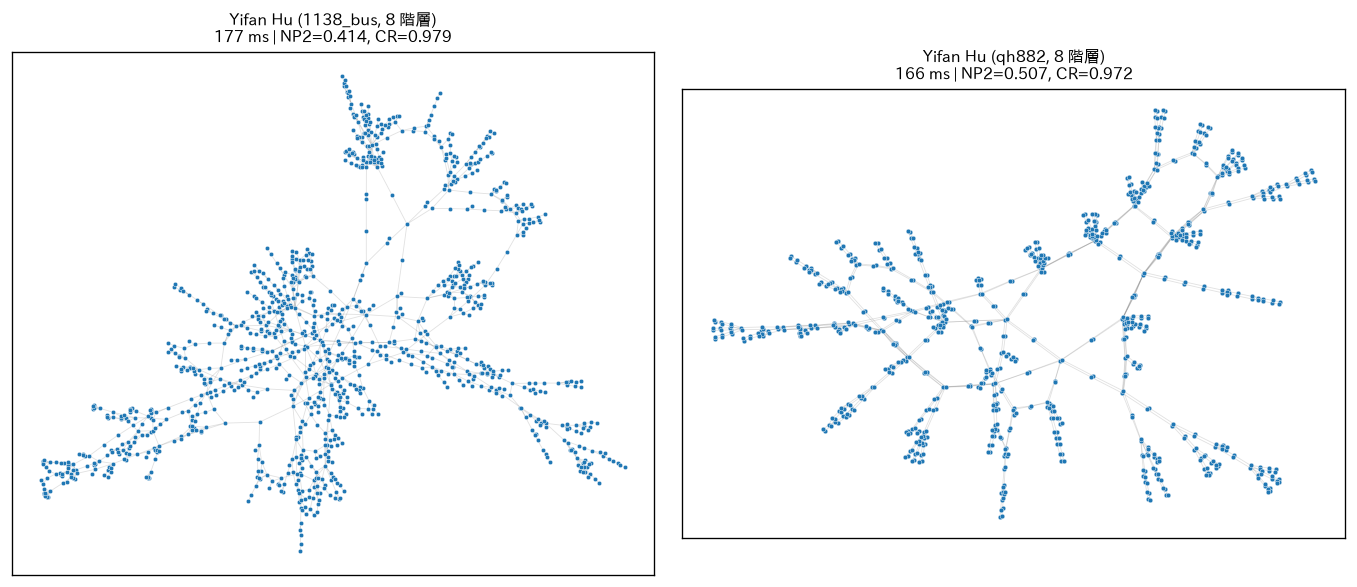

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8))

# Trace coarsening hierarchy progress on 1138_bus
lay_bus_yh = eg.Layout2d.init(g_bus.num_nodes, seed=42)
t0 = time.perf_counter()
yh_bus = eg.YifanHuSolver(g_bus, max_iterations_per_level=80, seed=42)
level_trace = []
while not yh_bus.is_finished:
    prev_lvl = yh_bus.current_level
    yh_bus.run_steps(lay_bus_yh, 80)
    level_trace.append((yh_bus.iteration, prev_lvl, yh_bus.current_level, yh_bus.status))
ms_bus = (time.perf_counter() - t0) * 1000.0
sns_b, np2_b, cr_b = eval_summary(g_bus, lay_bus_yh)
print(f"YifanHu (1138_bus): num_levels={yh_bus.num_levels}, time={ms_bus:.1f} ms, NP2={np2_b:.4f}")
print("Level trace (iter, start_lvl -> end_lvl, status):", level_trace[:6], "...", level_trace[-2:])
plot_graph_2d(
    g_bus,
    lay_bus_yh,
    axes[0],
    title=f"Yifan Hu (1138_bus, {yh_bus.num_levels} 階層)\n{ms_bus:.0f} ms | NP2={np2_b:.3f}, CR={cr_b:.3f}",
    node_size=7.0,
)

# Run on qh882 as well
lay_qh_yh = eg.Layout2d.init(g_qh.num_nodes, seed=42)
t0 = time.perf_counter()
yh_qh = eg.YifanHuSolver(g_qh, max_iterations_per_level=100, seed=42)
yh_qh.run(lay_qh_yh)
ms_qh = (time.perf_counter() - t0) * 1000.0
sns_q, np2_q, cr_q = eval_summary(g_qh, lay_qh_yh)
print(f"YifanHu (qh882): num_levels={yh_qh.num_levels}, time={ms_qh:.1f} ms, NP2={np2_q:.4f}")
plot_graph_2d(
    g_qh,
    lay_qh_yh,
    axes[1],
    title=f"Yifan Hu (qh882, {yh_qh.num_levels} 階層)\n{ms_qh:.0f} ms | NP2={np2_q:.3f}, CR={cr_q:.3f}",
    node_size=8.0,
)

plt.tight_layout()
plt.show()

\
## 6. 構造エントロピー変調 (`SelLayoutSolver`) と空間充填曲線 (`SfcLayoutSolver`)

- `SelLayoutSolver` は木構造ベースのエントロピーで各辺の構造重要度を求め、`mapping`（`"sigmoid"`, `"linear"`, `"tanh"`, `"custom_logistic"`, `"binary"`）により辺の重みを変調して `layout_backend`（`"fr"` / `"t_fdp"`）で配置します。`fr_config` / `t_fdp_config` 辞書で下流バックエンドのパラメータも細かく調整できます。  
  ※ 正方格子や 4-サイクルのように全辺の構造エントロピーが均一なグラフでは `modulated_weights()` がすべて 0 になるため、コミュニティ構造が不均一な `lesmis` のようなグラフで真価を発揮します。
- `SfcLayoutSolver` は階層的 Louvain 順序（`vertex_order()`）を 1 ステップ（`total_iterations == 1`）で `"hilbert"` または `"morton"` 曲線上の 2D グリッドへ配置します。

SEL [fr, sigmoid        ] se_target=0.1035 | w=[0.000, 0.334, 0.731] |   8.5 ms | NP2=0.3819
SEL [fr, linear         ] se_target=0.1035 | w=[0.000, 0.456, 0.999] |   6.7 ms | NP2=0.3885
SEL [fr, tanh           ] se_target=0.1035 | w=[0.000, 0.402, 0.881] |   6.5 ms | NP2=0.3805
SEL [fr, custom_logistic] se_target=0.1035 | w=[0.000, 0.055, 0.120] |   6.4 ms | NP2=0.3792
SEL [fr, binary         ] se_target=0.1035 | w=[0.000, 0.457, 1.000] |   6.6 ms | NP2=0.3724


SEL [t_fdp, sigmoid    ] se_target=0.1035 | 3180.5 ms | NP2=0.3808
SFC [hilbert] total_iters=1 order[:8]=[11, 26, 29, 34, 35, 36, 37, 38] |  0.35 ms | NP2=0.4532
SFC [morton ] total_iters=1 order[:8]=[11, 26, 29, 34, 35, 36, 37, 38] |  0.16 ms | NP2=0.4241


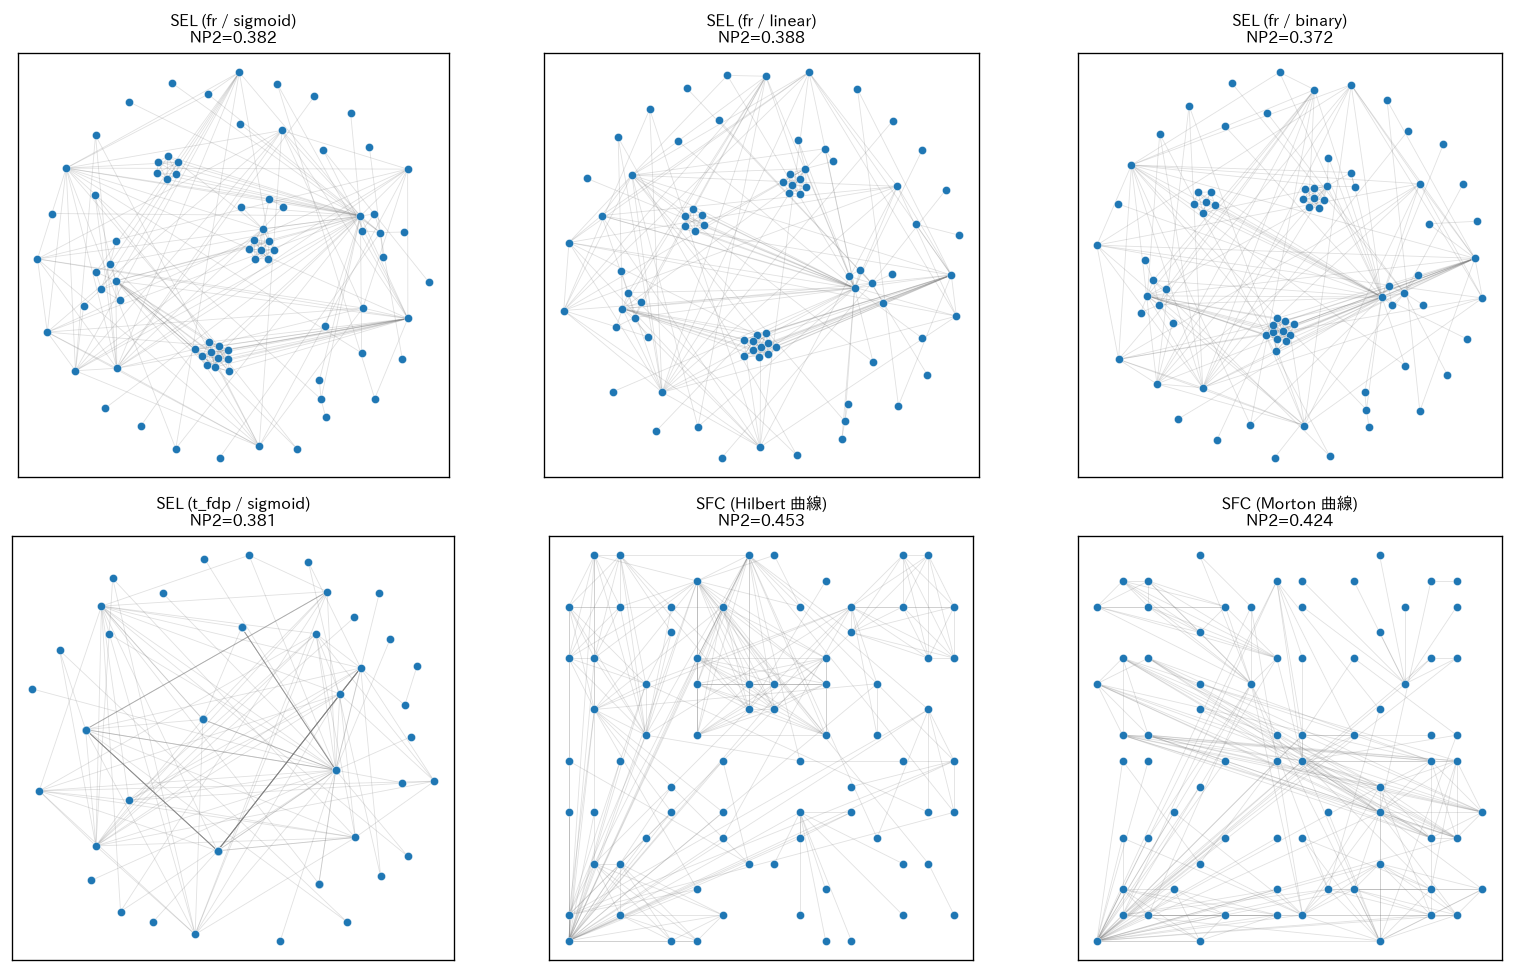

In [ ]:
\
sel_mappings = ["sigmoid", "linear", "tanh", "custom_logistic", "binary"]
sel_results = {}

for mp in sel_mappings:
    lay = eg.Layout2d.init(g_lesmis.num_nodes, seed=42)
    t0 = time.perf_counter()
    solver = eg.SelLayoutSolver(
        g_lesmis,
        mapping=mp,
        layout_backend="fr",
        iterations=150,
        fr_config={"gravity": 0.5},
        seed=42,
    )
    solver.run(lay)
    ms = (time.perf_counter() - t0) * 1000.0
    mw = solver.modulated_weights()
    sns, np2, cr = eval_summary(g_lesmis, lay)
    sel_results[mp] = (lay, ms, sns, np2, cr)
    print(
        f"SEL [fr, {mp:<15}] se_target={solver.se_target:.4f} | "
        f"w=[{mw.min():.3f}, {mw.mean():.3f}, {mw.max():.3f}] | {ms:5.1f} ms | NP2={np2:.4f}"
    )

# Also run SEL with layout_backend="t_fdp" and t_fdp_config
lay_sel_tfdp = eg.Layout2d.init(g_lesmis.num_nodes, seed=42)
t0 = time.perf_counter()
sel_tfdp = eg.SelLayoutSolver(
    g_lesmis,
    mapping="sigmoid",
    layout_backend="t_fdp",
    iterations=60,
    t_fdp_config={"alpha": 1.2},
    seed=42,
)
sel_tfdp.run(lay_sel_tfdp)
ms_tfdp = (time.perf_counter() - t0) * 1000.0
sns_tf, np2_tf, cr_tf = eval_summary(g_lesmis, lay_sel_tfdp)
print(f"SEL [t_fdp, sigmoid    ] se_target={sel_tfdp.se_target:.4f} | {ms_tfdp:5.1f} ms | NP2={np2_tf:.4f}")

# SfcLayoutSolver ("hilbert" vs "morton")
sfc_results = {}
for curve in ["hilbert", "morton"]:
    lay = eg.Layout2d.init(g_lesmis.num_nodes, seed=42)
    t0 = time.perf_counter()
    sfc = eg.SfcLayoutSolver(g_lesmis, curve=curve, scale=100.0, seed=42)
    sfc.run(lay)
    ms = (time.perf_counter() - t0) * 1000.0
    vorder = sfc.vertex_order()
    sns, np2, cr = eval_summary(g_lesmis, lay)
    sfc_results[curve] = (lay, ms, sns, np2, cr)
    print(
        f"SFC [{curve:<7}] total_iters={sfc.total_iterations} order[:8]={vorder[:8].tolist()} | "
        f"{ms:5.2f} ms | NP2={np2:.4f}"
    )

fig, axes = plt.subplots(2, 3, figsize=(13.5, 8.2))
plot_graph_2d(g_lesmis, sel_results["sigmoid"][0], axes[0, 0], f"SEL (fr / sigmoid)\nNP2={sel_results['sigmoid'][3]:.3f}", node_size=24.0)
plot_graph_2d(g_lesmis, sel_results["linear"][0], axes[0, 1], f"SEL (fr / linear)\nNP2={sel_results['linear'][3]:.3f}", node_size=24.0)
plot_graph_2d(g_lesmis, sel_results["binary"][0], axes[0, 2], f"SEL (fr / binary)\nNP2={sel_results['binary'][3]:.3f}", node_size=24.0)
plot_graph_2d(g_lesmis, lay_sel_tfdp, axes[1, 0], f"SEL (t_fdp / sigmoid)\nNP2={np2_tf:.3f}", node_size=24.0)
plot_graph_2d(g_lesmis, sfc_results["hilbert"][0], axes[1, 1], f"SFC (Hilbert 曲線)\nNP2={sfc_results['hilbert'][3]:.3f}", node_size=24.0)
plot_graph_2d(g_lesmis, sfc_results["morton"][0], axes[1, 2], f"SFC (Morton 曲線)\nNP2={sfc_results['morton'][3]:.3f}", node_size=24.0)
plt.tight_layout()
plt.show()

\
## 7. 四辺形バックボーン抽出 (`extract_quadrilateral_backbone`, `BackboneSolver`) と粗視化初期化 (`coarse_backbone_init`)

- `extract_quadrilateral_backbone` は、すべてのグラフ辺から Simmelian 四辺形重みと UMST（Union of Minimum Spanning Trees）に基づき骨格辺 (`backbone_edges`, `umst_edges`, `backbone_csr`) を抽出します。既定では **`use_weights=True`**（重み付きグラフの辺重みを考慮）であり、`use_weights=False` を指定すると純粋な無向単純位相のみからバックボーンを抽出します。
- `BackboneSolver` は抽出したバックボーン重み付きグラフに対して `layout_mode` (`"stress"` / `"sgd"`) でレイアウトを解き、`backbone_result()` から抽出結果を取得できます。
- `coarse_backbone_init` は多段階 Louvain 粗視化グラフ上で `edge_length_mode`（`"conductance_inverse"` / `"resistance_curvature_flow"`）と `distance_backend`（`"rhgh"` / `"chebyshev_dog"` / `"shortest_path"`）を組み合わせて高速に初期配置を生成します。無向グラフが必須ですが、`poli` のような**非連結グラフでも正常に動作**します。

extract_quadrilateral_backbone (lesmis): total_edges=254, umst_edges=111, backbone_edges=149, use_weights=False matches unweighted=True, use_weights=True edges=146
BackboneSolver [stress]   22.3 ms | umst=111 | SNS=0.1942 NP2=0.5642 CR=0.8117
BackboneSolver [sgd   ]    7.9 ms | umst=111 | SNS=0.1962 NP2=0.5598 CR=0.8169
coarse_backbone_init [conductance / rhgh         ] coarse= 26 nodes levels=1 |   4.8 ms | SNS=0.1827 NP2=0.1056
coarse_backbone_init [conductance / chebyshev_dog] coarse= 26 nodes levels=1 |   5.5 ms | SNS=0.2925 NP2=0.1055


coarse_backbone_init [conductance / shortest_path] coarse= 26 nodes levels=1 |   3.8 ms | SNS=0.1524 NP2=0.1055
coarse_backbone_init [resistance_ / rhgh         ] coarse= 26 nodes levels=1 |   5.9 ms | SNS=0.1759 NP2=0.1056
coarse_backbone_init [resistance_ / chebyshev_dog] coarse= 26 nodes levels=1 |   6.4 ms | SNS=0.3131 NP2=0.1055


coarse_backbone_init (disconnected poli): 154.3 ms | coarse_nodes=209, coarse_edges=73, coarse_overlap_final=0


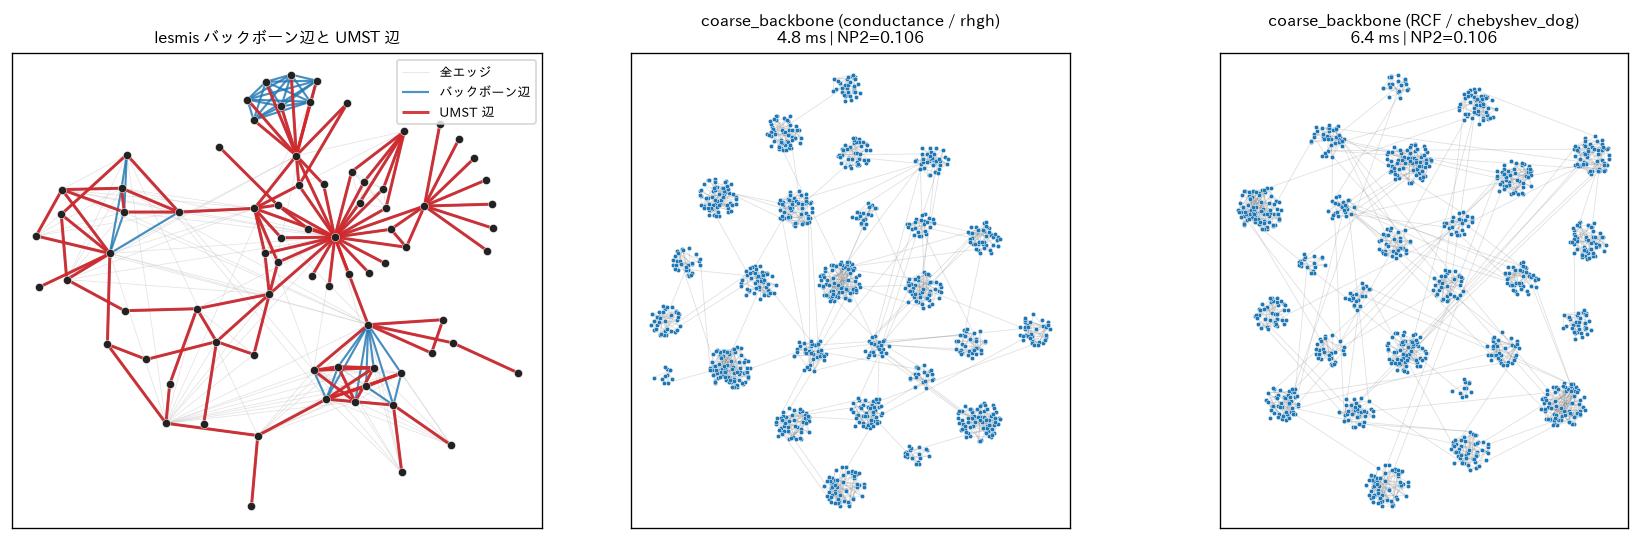

In [ ]:
\
# 1) extract_quadrilateral_backbone (use_weights=True vs use_weights=False) & BackboneSolver on lesmis
bb_dict = eg.extract_quadrilateral_backbone(g_lesmis, retain_ratio=0.25)
indptr_lm, indices_lm = g_lesmis.indptr(), g_lesmis.indices()
w_edges_lm = [(u, int(v)) for u in range(g_lesmis.num_nodes) for v in indices_lm[int(indptr_lm[u]) : int(indptr_lm[u + 1])] if u < int(v)]
g_lesmis_w = eg.CsrGraph.from_edge_list(g_lesmis.num_nodes, w_edges_lm, weights=np.linspace(0.1, 50.0, len(w_edges_lm)), directed=False)
bb_dict_w_unweighted = eg.extract_quadrilateral_backbone(g_lesmis_w, retain_ratio=0.25, use_weights=False)
bb_dict_w_weighted = eg.extract_quadrilateral_backbone(g_lesmis_w, retain_ratio=0.25, use_weights=True)
assert np.array_equal(bb_dict["backbone_edges"], bb_dict_w_unweighted["backbone_edges"])
print(
    f"extract_quadrilateral_backbone (lesmis): total_edges={g_lesmis.num_edges}, "
    f"umst_edges={len(bb_dict['umst_edges'])}, backbone_edges={len(bb_dict['backbone_edges'])}, "
    f"use_weights=False matches unweighted=True, use_weights=True edges={len(bb_dict_w_weighted['backbone_edges'])}"
)

for mode in ["stress", "sgd"]:
    lay_bb = eg.Layout2d.init(g_lesmis.num_nodes, seed=42)
    t0 = time.perf_counter()
    bb_solver = eg.BackboneSolver(g_lesmis, retain_ratio=0.25, layout_mode=mode, iterations=80, seed=42)
    bb_solver.run(lay_bb)
    ms_bb = (time.perf_counter() - t0) * 1000.0
    res = bb_solver.backbone_result()
    sns, np2, cr = eval_summary(g_lesmis, lay_bb)
    print(f"BackboneSolver [{mode:<6}] {ms_bb:6.1f} ms | umst={len(res['umst_edges'])} | SNS={sns:.4f} NP2={np2:.4f} CR={cr:.4f}")
    if mode == "sgd":
        lay_bb_vis = lay_bb

# 2) coarse_backbone_init across edge_length_mode & distance_backend on 1138_bus
cb_configs = [
    ("conductance_inverse", "rhgh"),
    ("conductance_inverse", "chebyshev_dog"),
    ("conductance_inverse", "shortest_path"),
    ("resistance_curvature_flow", "rhgh"),
    ("resistance_curvature_flow", "chebyshev_dog"),
]
cb_layouts = {}
for elm, db in cb_configs:
    t0 = time.perf_counter()
    out = eg.coarse_backbone_init(g_bus, edge_length_mode=elm, distance_backend=db, seed=42)
    ms = (time.perf_counter() - t0) * 1000.0
    fine_lay = out["fine_layout"]
    sns, np2, cr = eval_summary(g_bus, fine_lay)
    st = out["stats"]
    cb_layouts[(elm, db)] = (fine_lay, ms, sns, np2, cr)
    print(
        f"coarse_backbone_init [{elm[:11]} / {db:<13}] coarse={st['num_coarse_nodes']:>3} nodes "
        f"levels={st['louvain_levels']} | {ms:5.1f} ms | SNS={sns:.4f} NP2={np2:.4f}"
    )

# 3) Verify coarse_backbone_init on disconnected 'poli'
t0 = time.perf_counter()
out_poli = eg.coarse_backbone_init(g_poli, edge_length_mode="conductance_inverse", distance_backend="rhgh", seed=42)
ms_poli = (time.perf_counter() - t0) * 1000.0
assert out_poli["fine_layout"].is_all_finite()
print(
    f"coarse_backbone_init (disconnected poli): {ms_poli:.1f} ms | "
    f"coarse_nodes={out_poli['stats']['num_coarse_nodes']}, "
    f"coarse_edges={out_poli['stats']['num_coarse_edges']}, "
    f"coarse_overlap_final={out_poli['stats']['coarse_overlap_pairs_final']}"
)

# Visualize extracted backbone edges + two coarse_backbone_init configurations
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.6))

# Panel 1: lesmis with highlighted backbone_edges & umst_edges
ax0 = axes[0]
coords_bb = lay_bb_vis.coords(copy=False)
indptr, indices = g_lesmis.indptr(), g_lesmis.indices()
all_segs = [
    [coords_bb[u], coords_bb[int(v)]]
    for u in range(g_lesmis.num_nodes)
    for v in indices[int(indptr[u]) : int(indptr[u + 1])]
    if u < int(v)
]
bb_segs = [[coords_bb[int(u)], coords_bb[int(v)]] for u, v in bb_dict["backbone_edges"]]
umst_segs = [[coords_bb[int(u)], coords_bb[int(v)]] for u, v in bb_dict["umst_edges"]]
ax0.add_collection(LineCollection(all_segs, colors="#cccccc", linewidths=0.5, alpha=0.5, zorder=1, label="全エッジ"))
ax0.add_collection(LineCollection(bb_segs, colors="#1f77b4", linewidths=1.3, alpha=0.8, zorder=2, label="バックボーン辺"))
ax0.add_collection(LineCollection(umst_segs, colors="#d62728", linewidths=1.8, alpha=0.9, zorder=3, label="UMST 辺"))
ax0.scatter(coords_bb[:, 0], coords_bb[:, 1], s=24, c="#222222", edgecolors="white", linewidths=0.3, zorder=4)
ax0.set_aspect("equal")
ax0.autoscale_view()
ax0.set_xticks([])
ax0.set_yticks([])
ax0.legend(loc="upper right", fontsize=8)
ax0.set_title("lesmis バックボーン辺と UMST 辺", fontsize=9.5)

lay_cb1, ms1, _, np2_1, _ = cb_layouts[("conductance_inverse", "rhgh")]
plot_graph_2d(g_bus, lay_cb1, axes[1], title=f"coarse_backbone (conductance / rhgh)\n{ms1:.1f} ms | NP2={np2_1:.3f}", node_size=7.0)

lay_cb2, ms2, _, np2_2, _ = cb_layouts[("resistance_curvature_flow", "chebyshev_dog")]
plot_graph_2d(g_bus, lay_cb2, axes[2], title=f"coarse_backbone (RCF / chebyshev_dog)\n{ms2:.1f} ms | NP2={np2_2:.3f}", node_size=7.0)

plt.tight_layout()
plt.show()

## 8. 統合比較ベンチマーク（`qh882`）

同一グラフ `qh882`（`N=882, E=1533`）上で各ソルバの計算時間・SNS（低いほど良好）・NP2（高いほど良好）・Crosslessness（高いほど良好）を比較します。

アルゴリズム                      時間 (ms)    SNS (↓)    NP2 (↑)  Crossless (↑)
------------------------------------------------------------------------
ForceAtlas2 (BH)              157.8     0.1662     0.4996         0.9689
ForceAtlas2 (LinLog)          167.4     0.3678     0.4152         0.9412
YifanHu                       161.2     0.0819     0.5074         0.9720
FR (Exact)                    362.3     0.1722     0.3527         0.9613
FR (Barnes-Hut)                86.3     0.1404     0.3958         0.9649
FR (Grid)                      77.0     0.1979     0.2828         0.9532
LinLog (Edge)                 171.4     0.5040     0.1733         0.8089
GEM (max_iterations=150)      549.6     0.1263     0.4020         0.9637
SEL (FR / sigmoid)            745.4     0.5083     0.3951         0.7945
SFC (Hilbert)                   1.9     0.3275     0.1904         0.9059
Backbone (SGD)               1497.1     0.0481     0.4246         0.9614
coarse_backbone (rHGH)          6.3     0.1404     

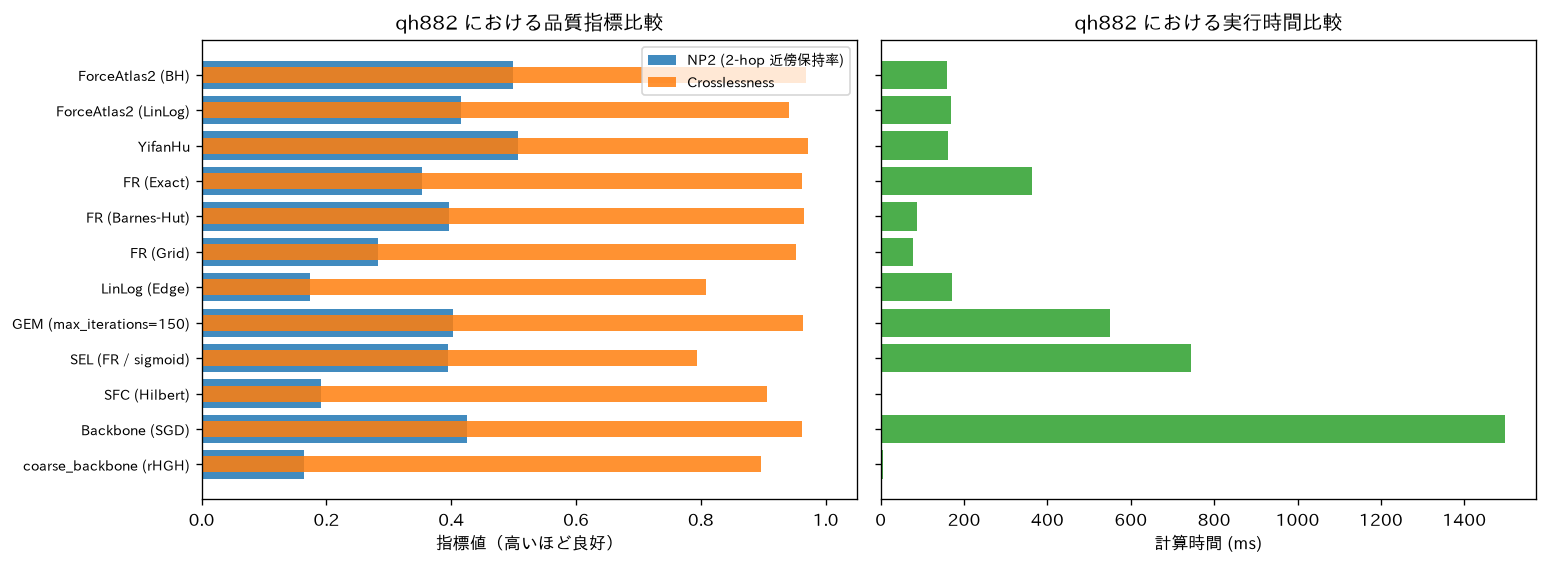

In [ ]:
\
bench_rows = []


def run_bench(name: str, fn):
    t0 = time.perf_counter()
    lay = fn()
    ms = (time.perf_counter() - t0) * 1000.0
    assert lay.is_all_finite()
    sns, np2, cr = eval_summary(g_qh, lay)
    bench_rows.append((name, ms, sns, np2, cr))


def _solve(solver_cls, **kwargs):
    lay = eg.Layout2d.init(g_qh.num_nodes, seed=42)
    solver_cls(g_qh, seed=42, **kwargs).run(lay)
    return lay


run_bench("ForceAtlas2 (BH)", lambda: _solve(eg.ForceAtlas2Solver, iterations=200, use_barnes_hut=True))
run_bench("ForceAtlas2 (LinLog)", lambda: _solve(eg.ForceAtlas2Solver, iterations=200, linlog_mode=True))
run_bench("YifanHu", lambda: _solve(eg.YifanHuSolver, max_iterations_per_level=100))
run_bench("FR (Exact)", lambda: _solve(eg.FruchtermanReingoldSolver, iterations=120, backend="exact"))
run_bench("FR (Barnes-Hut)", lambda: _solve(eg.FruchtermanReingoldSolver, iterations=120, backend="barnes_hut"))
run_bench("FR (Grid)", lambda: _solve(eg.FruchtermanReingoldSolver, iterations=120, backend="grid"))
run_bench("LinLog (Edge)", lambda: _solve(eg.LinLogSolver, iterations=200, repulsion_model="edge_repulsion"))
run_bench("GEM (max_iterations=150)", lambda: _solve(eg.GemSolver, max_iterations=150))
run_bench("SEL (FR / sigmoid)", lambda: _solve(eg.SelLayoutSolver, mapping="sigmoid", layout_backend="fr", iterations=150))
run_bench("SFC (Hilbert)", lambda: _solve(eg.SfcLayoutSolver, curve="hilbert"))
run_bench("Backbone (SGD)", lambda: _solve(eg.BackboneSolver, layout_mode="sgd", iterations=60))
run_bench("coarse_backbone (rHGH)", lambda: eg.coarse_backbone_init(g_qh, distance_backend="rhgh", seed=42)["fine_layout"])

print(f"{'アルゴリズム':<24} {'時間 (ms)':>10} {'SNS (↓)':>10} {'NP2 (↑)':>10} {'Crossless (↑)':>14}")
print("-" * 72)
for name, ms, sns, np2, cr in bench_rows:
    print(f"{name:<24} {ms:>10.1f} {sns:>10.4f} {np2:>10.4f} {cr:>14.4f}")

names = [r[0] for r in bench_rows]
times = [r[1] for r in bench_rows]
np2s = [r[3] for r in bench_rows]
crs = [r[4] for r in bench_rows]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
y_pos = np.arange(len(names))
axes[0].barh(y_pos, np2s, color="#1f77b4", alpha=0.85, label="NP2 (2-hop 近傍保持率)")
axes[0].barh(y_pos, crs, height=0.45, color="#ff7f0e", alpha=0.85, label="Crosslessness")
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(names, fontsize=8.5)
axes[0].invert_yaxis()
axes[0].set_xlim(0, 1.05)
axes[0].set_xlabel("指標値（高いほど良好）")
axes[0].set_title("qh882 における品質指標比較")
axes[0].legend(fontsize=8.5)

axes[1].barh(y_pos, times, color="#2ca02c", alpha=0.85)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels([])
axes[1].invert_yaxis()
axes[1].set_xlabel("計算時間 (ms)")
axes[1].set_title("qh882 における実行時間比較")

plt.tight_layout()
plt.show()